# ANA-064 — RUN-166 paired readouts and embedded neighbourhoods

**EXP-065 · RUN-166 · TrpB · descriptive analysis, 7 October 2026**

The main signal is the value of a strong nonadditive latent component. The extra contribution of sigmoid curvature is modest and uncertain at the primary resolution. Matching the observable amplitude brings fitness spread close to the measured panel, while high-order WHT fractions and beneficial-mutation slopes remain different. Embedding the fitted readouts shows that local variation survives through length 512, but random-background saturation and dilution of interactions among four sampled sites limit statistical transfer.

These are observations about aggregate distributions under specified sampling. They do not identify TrpB interactions, molecular free energies, or a universally empirical synthetic landscape. No numerical scientific acceptance criteria are applied.


## What was compared

The two readouts share exactly the same additive and GNK latent fields:

\[
y_\mathrm{linear}=b+c(A+rG),\qquad
y_\mathrm{sigmoid}=b+c\,\sigma[\mathrm{logit}(p_0)+\beta(A+rG)].
\]

Each candidate's positive scale and offset were fitted only to the empirical calibration panel, matching mean within-cube SD and overall mean. They are frozen thereafter. The four latent ratios are 0, 0.25, 1 and 4; sigmoid curvature is selected separately within each ratio. Rank 8 and latent order weights (0.35, 0.45, 0.20) were fixed prospectively using the previous TrpB result. This is a follow-up informed by RUN-164, with fresh genotypes and seeds.

There are 24 empirical calibration cubes and 24 genotype-disjoint confirmation cubes, excluding all 768 prior RUN-164 TrpB genotypes and 128 engineering-test genotypes. Synthetic calibration uses four seeds × eight cubes; confirmation uses eight new seeds × eight cubes per arm. The assay is the prepared Johnston et al. TrpB four-site dataset, whose 159,129 measured variants are checked against the input hash and saved cube values. Each cube has 16 nodes and 32 oriented edges. Sampling is conditional on complete measurement, not on activity.

The distance compares the joint distribution of ten descriptors in an embedding standardized on empirical calibration cubes, with a scale floor of 0.05 and explicit availability indicators. It is a descriptive discrepancy, not a percentage of empirical realism. Distances from RUN-164 are not directly comparable numerically: this RUN changes the empirical panel, fitted embedding, and readout calibration. The primary resolution is 0.001 of the empirical calibration fitness range; 10⁻¹² and 0.01 are sensitivity settings, not inferred noise levels.

WHT power is the sum of squared orthonormal contrast coefficients of a complete **four-site binary cube**, excluding its mean. The fraction at orders ≥3 divides that power by total nonconstant variance, only when variance exceeds max(10⁻¹⁸, resolution²). This is not a whole-protein WHT. Diminishing returns is the slope of a fixed 0→1 mutation's effect against its eight background fitnesses; a mutation is called beneficial by its mean effect across backgrounds. Eligible mutation slopes are averaged within cubes. Missing slopes and spectra are reported as unavailable, never as zero.

Uncertainty uses 2,000 paired resamples (seed 664001) of 24 empirical cubes and eight synthetic **seed clusters**, retaining all eight cubes in a sampled seed. Parameters and empirical standardization remain fixed. The percentile intervals exclude calibration uncertainty, assay error and dependence through shared sites/alleles; they are conditional descriptions, not universal confidence guarantees. Embedded results have only three seeds per length/rank and are reported as descriptive means, availability counts and seed-specific tables.


## Load and audit the frozen record

This cell checks the data before deriving any comparisons. Restore both DVC data bundles first; see the README.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
# Works from the notebook folder or any project subdirectory.
folder = Path.cwd().resolve()
while not (folder / 'labproject.yaml').exists() and folder != folder.parent:
    folder = folder.parent
notebooks = folder / 'analyses/2026-10-07_ANA-064_run-166-paired-readouts-and-embedded-neighbourhoods/notebooks'
sys.path.insert(0, str(notebooks))
import analysis_tools as a
ctx = a.load_and_audit()
display({k: v for k, v in ctx['audit'].items() if k != 'metric_max_absolute_errors'})

{'run': 'RUN-166',
 'remote_output_log_checksums': 20,
 'source_hashes': 9,
 'input_hashes': 2,
 'unique_empirical_nodes': 768,
 'excluded_prior_and_engineering_nodes': 896,
 'all_empirical_values_verified_against_prepared_table': True,
 'latent_cubes': 1248,
 'replayed_observed_cubes': 3312,
 'independent_statistic_rows': 9936,
 'verified_oriented_edges': 105984,
 'readout_replay_max_absolute_error': 1.1102230246251565e-16,
 'calibration_candidates_affine_and_loss_recomputed': 40,
 'paired_strict_edges': [{'ratio': 0.0,
   'edges': 2048,
   'opposite_sign_edges': 0,
   'sign_or_tie_differences': 0},
  {'ratio': 0.25,
   'edges': 2048,
   'opposite_sign_edges': 0,
   'sign_or_tie_differences': 0},
  {'ratio': 1.0,
   'edges': 2048,
   'opposite_sign_edges': 0,
   'sign_or_tie_differences': 0},
  {'ratio': 4.0,
   'edges': 2048,
   'opposite_sign_edges': 0,
   'sign_or_tie_differences': 0}],
 'replay_scope': 'Saved latents and frozen readouts; no claim of regenerating GNK coefficients a

## Paired conditional uncertainty

Resample empirical cubes and synthetic seed clusters with common weights for paired arms. No parameters are refitted.

In [2]:
a.summarize(ctx, draws=2000, seed=664001)
display(ctx['contrasts'])
display(ctx['descriptors'].query("ratio == 4 or readout == 'empirical'"))

,resolution,ratio,delta_sigmoid_minus_linear,low,high
0,1.000000e-12,0.00,-0.296410,-0.341170,-0.228575
1,1.000000e-12,0.25,-0.245886,-0.293222,-0.185274
2,1.000000e-12,1.00,-0.054509,-0.082484,-0.024406
3,1.000000e-12,4.00,-0.059801,-0.093629,-0.025016
4,1.000000e-03,0.00,-0.324720,-0.393499,-0.235208
5,1.000000e-03,0.25,-0.022245,-0.128195,0.119426
6,1.000000e-03,1.00,-0.020312,-0.045419,0.007017
7,1.000000e-03,4.00,-0.016631,-0.064688,0.073366
8,1.000000e-02,0.00,-0.361868,-0.666736,-0.030263
9,1.000000e-02,0.25,-0.390246,-0.688380,-0.091077


,readout,ratio,metric,mean,median,available,total,low,high,bootstrap_available
0,empirical,NaN,fitness_sd,0.056442,0.031750,24,24,0.034911,0.082948,2000
1,empirical,NaN,walsh_epistatic_fraction,0.661917,0.715139,24,24,0.573366,0.743239,2000
2,empirical,NaN,walsh_high_order_fraction,0.266817,0.226484,24,24,0.197998,0.343997,2000
3,empirical,NaN,beneficial_diminishing_returns_slope,-1.029183,-1.011223,24,24,-1.268106,-0.795055,2000
4,empirical,NaN,reference_beneficial_fraction,0.604167,0.625000,24,24,0.468750,0.739583,2000
...,...,...,...,...,...,...,...,...,...,...
193,sigmoid,4.0,walsh_energy_order_4,0.000057,0.000016,64,64,0.000025,0.000104,2000
194,sigmoid,4.0,walsh_fraction_order_1,0.479627,0.486517,64,64,0.428619,0.520686,2000
195,sigmoid,4.0,walsh_fraction_order_2,0.376202,0.347808,64,64,0.353503,0.401391,2000
196,sigmoid,4.0,walsh_fraction_order_3,0.129157,0.105269,64,64,0.095326,0.162592,2000


## 1. Interaction strength explains more than readout choice

At the calibration-selected **r = 4**, held-out joint distance is **0.2784 linear** and **0.2617 sigmoid**. Their paired difference, sigmoid minus linear, is **−0.0166 [−0.0647, +0.0734]**. Both readouts become much closer to measured TrpB as r rises across the tested grid. The preferred r is the upper boundary, so an interior optimum has not been located.

Mean within-cube SD is **0.0564 measured, 0.0654 linear, 0.0599 sigmoid**. The corresponding mean high-order WHT fractions are **0.2668, 0.1127 and 0.1442**. Thus amplitude agreement coexists with a substantial remaining discrepancy in variance allocation. The sigmoid increases the high-order fraction here, but does not reproduce its empirical distribution.

**Figure 1.** Points are confirmation estimates; whiskers and the grey empirical band are conditional 95% bootstrap intervals. The paired difference uses common empirical and seed resampling weights. The evenly spaced ratio labels are discrete candidates, not a linear r axis.


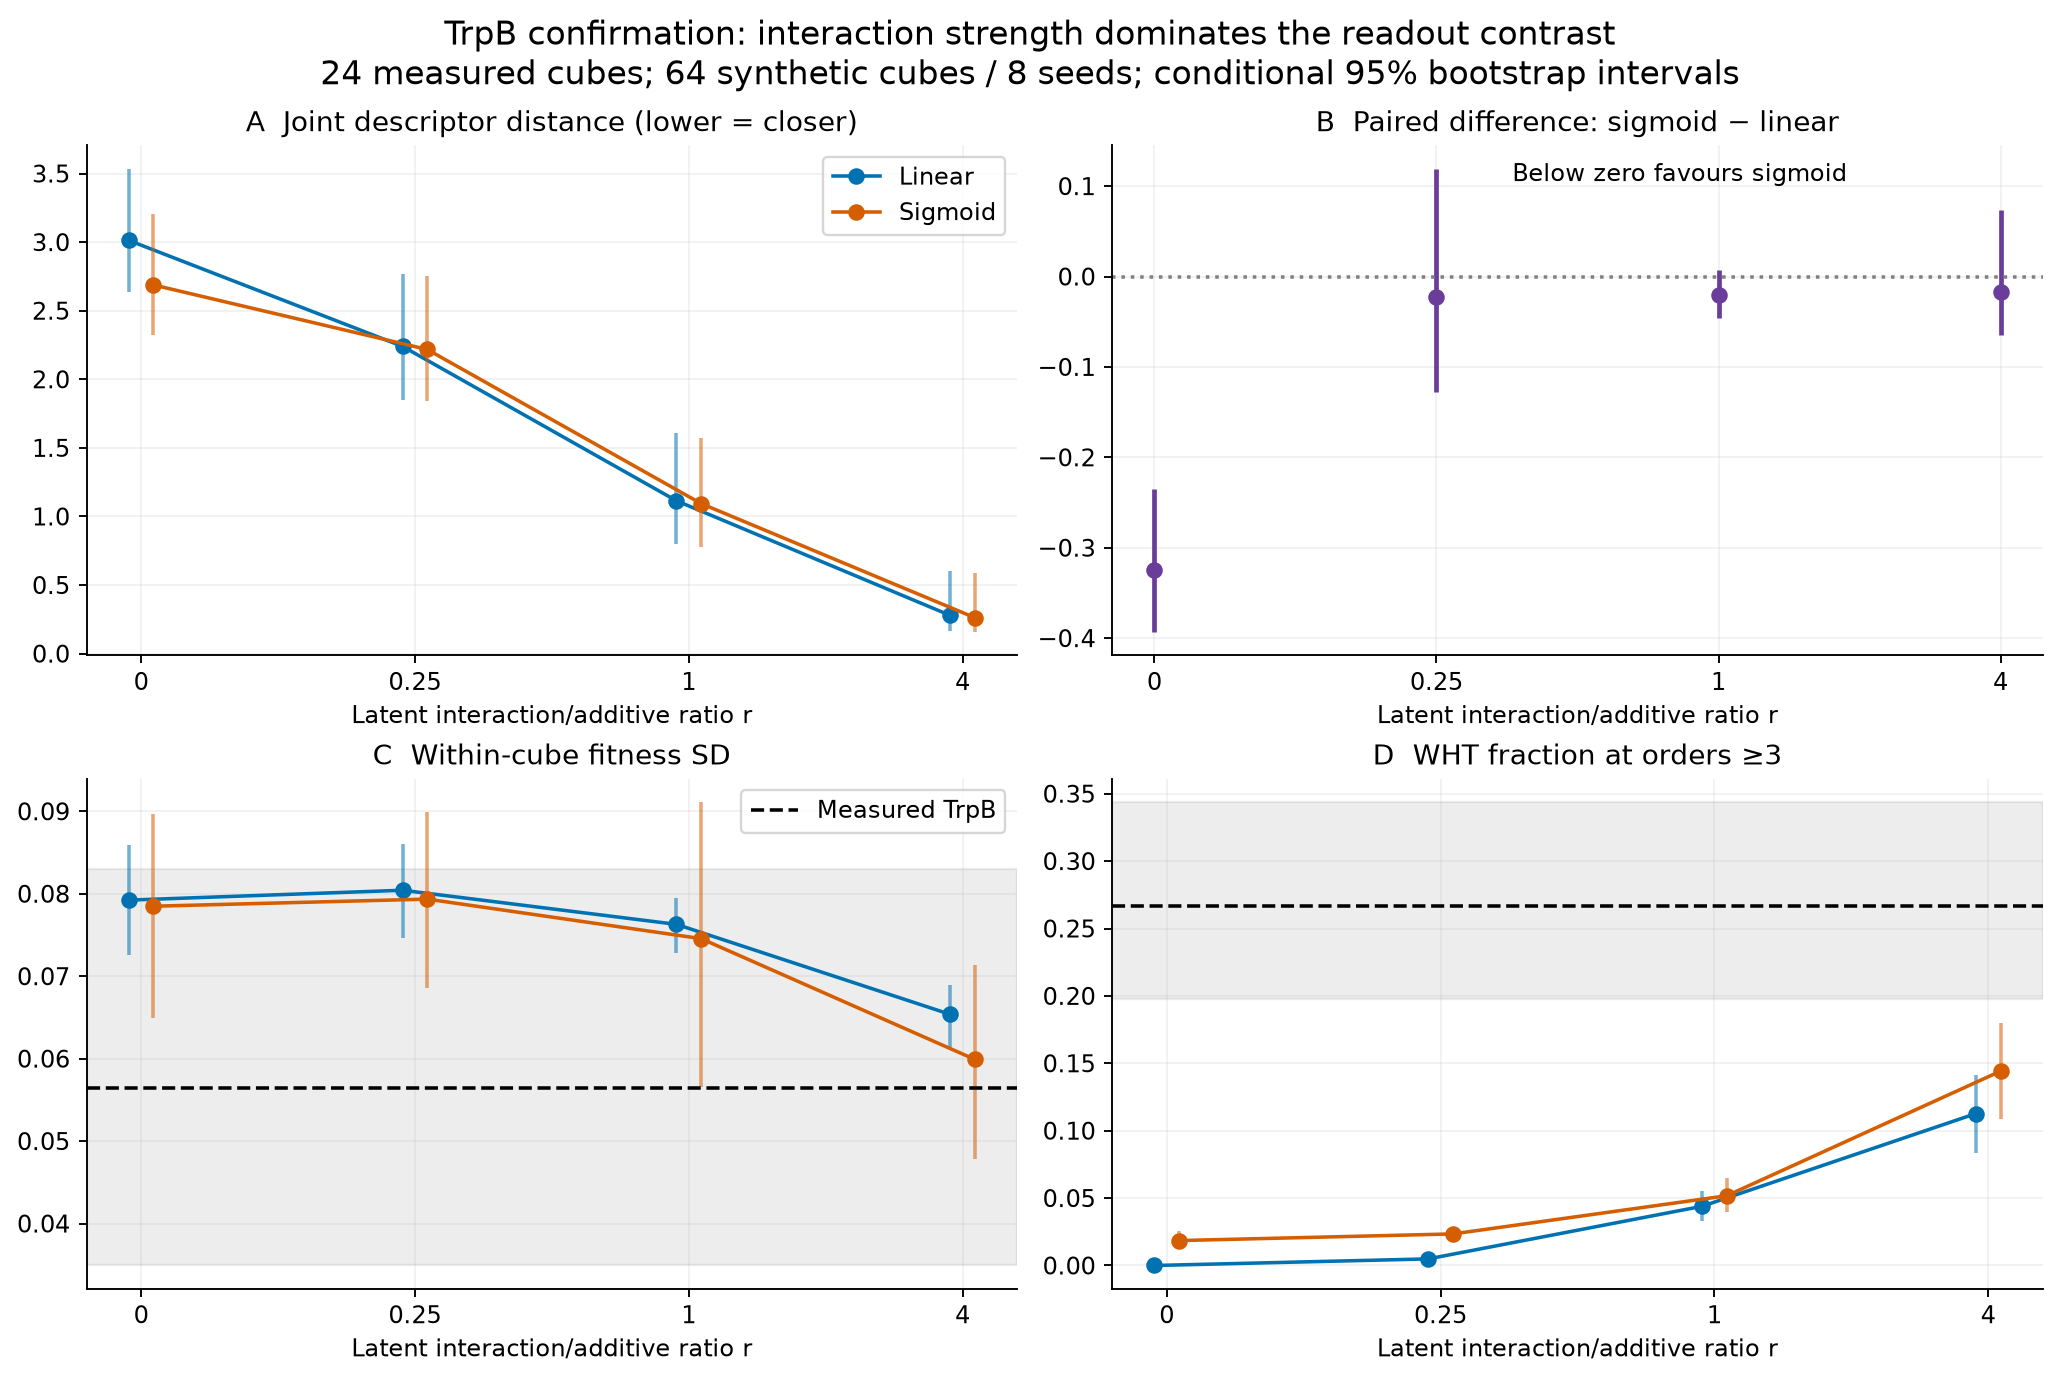

In [3]:
display(Image(filename=str(a.figure_pairs(ctx))))

## 2. Operating position changes several statistics together

At r = 4 the mean beneficial-mutation slope is **−1.029 measured**, **−0.577 linear**, and **−0.500 sigmoid**. Available cube summaries are respectively **24/24, 58/64 and 60/64**. The sigmoid does not improve this mean slope; some low-fitness cubes show increasing returns. Its median slope is −0.642, so the mean alone also hides a heterogeneous pattern.

Changing only p₀ from 0.1 to 0.5 to 0.9 moves the mean slope **−0.331 → −0.665 → −0.770**, while mean fitness rises **0.118 → 0.194 → 0.258** and neutral-edge fraction rises **0.042 → 0.074 → 0.206**. Slope availability declines from 61/64 to 53/64. Absolute high-order power falls from **4.67×10⁻⁴ to 3.36×10⁻⁴**, even as its mean fraction rises from **0.147 to 0.173**. The latter also excludes two unresolved cubes at p₀ = 0.9. Relative epistasis can increase while absolute variation shrinks.

These are paired mechanistic interventions with r, β, b and c frozen, not three newly fitted empirical models. Changing p₀ moves the sampled observable-fitness distribution; the cross-cube plots are descriptive conditional relationships, not estimates of a causal fitness response at fixed fitness. They show the flexibility of curvature without uniquely identifying a thermodynamic mechanism.

**Figure 2.** One point per cube. Black crosses are measured TrpB; the top row compares frozen readouts, and the bottom row changes p₀ on the same latent cubes. Vertical guides are empirical calibration quartiles. Power uses a log axis, slopes a symmetric-log axis; availability is printed below each panel. No unrelated mutation identities are pooled into a fitted regression.


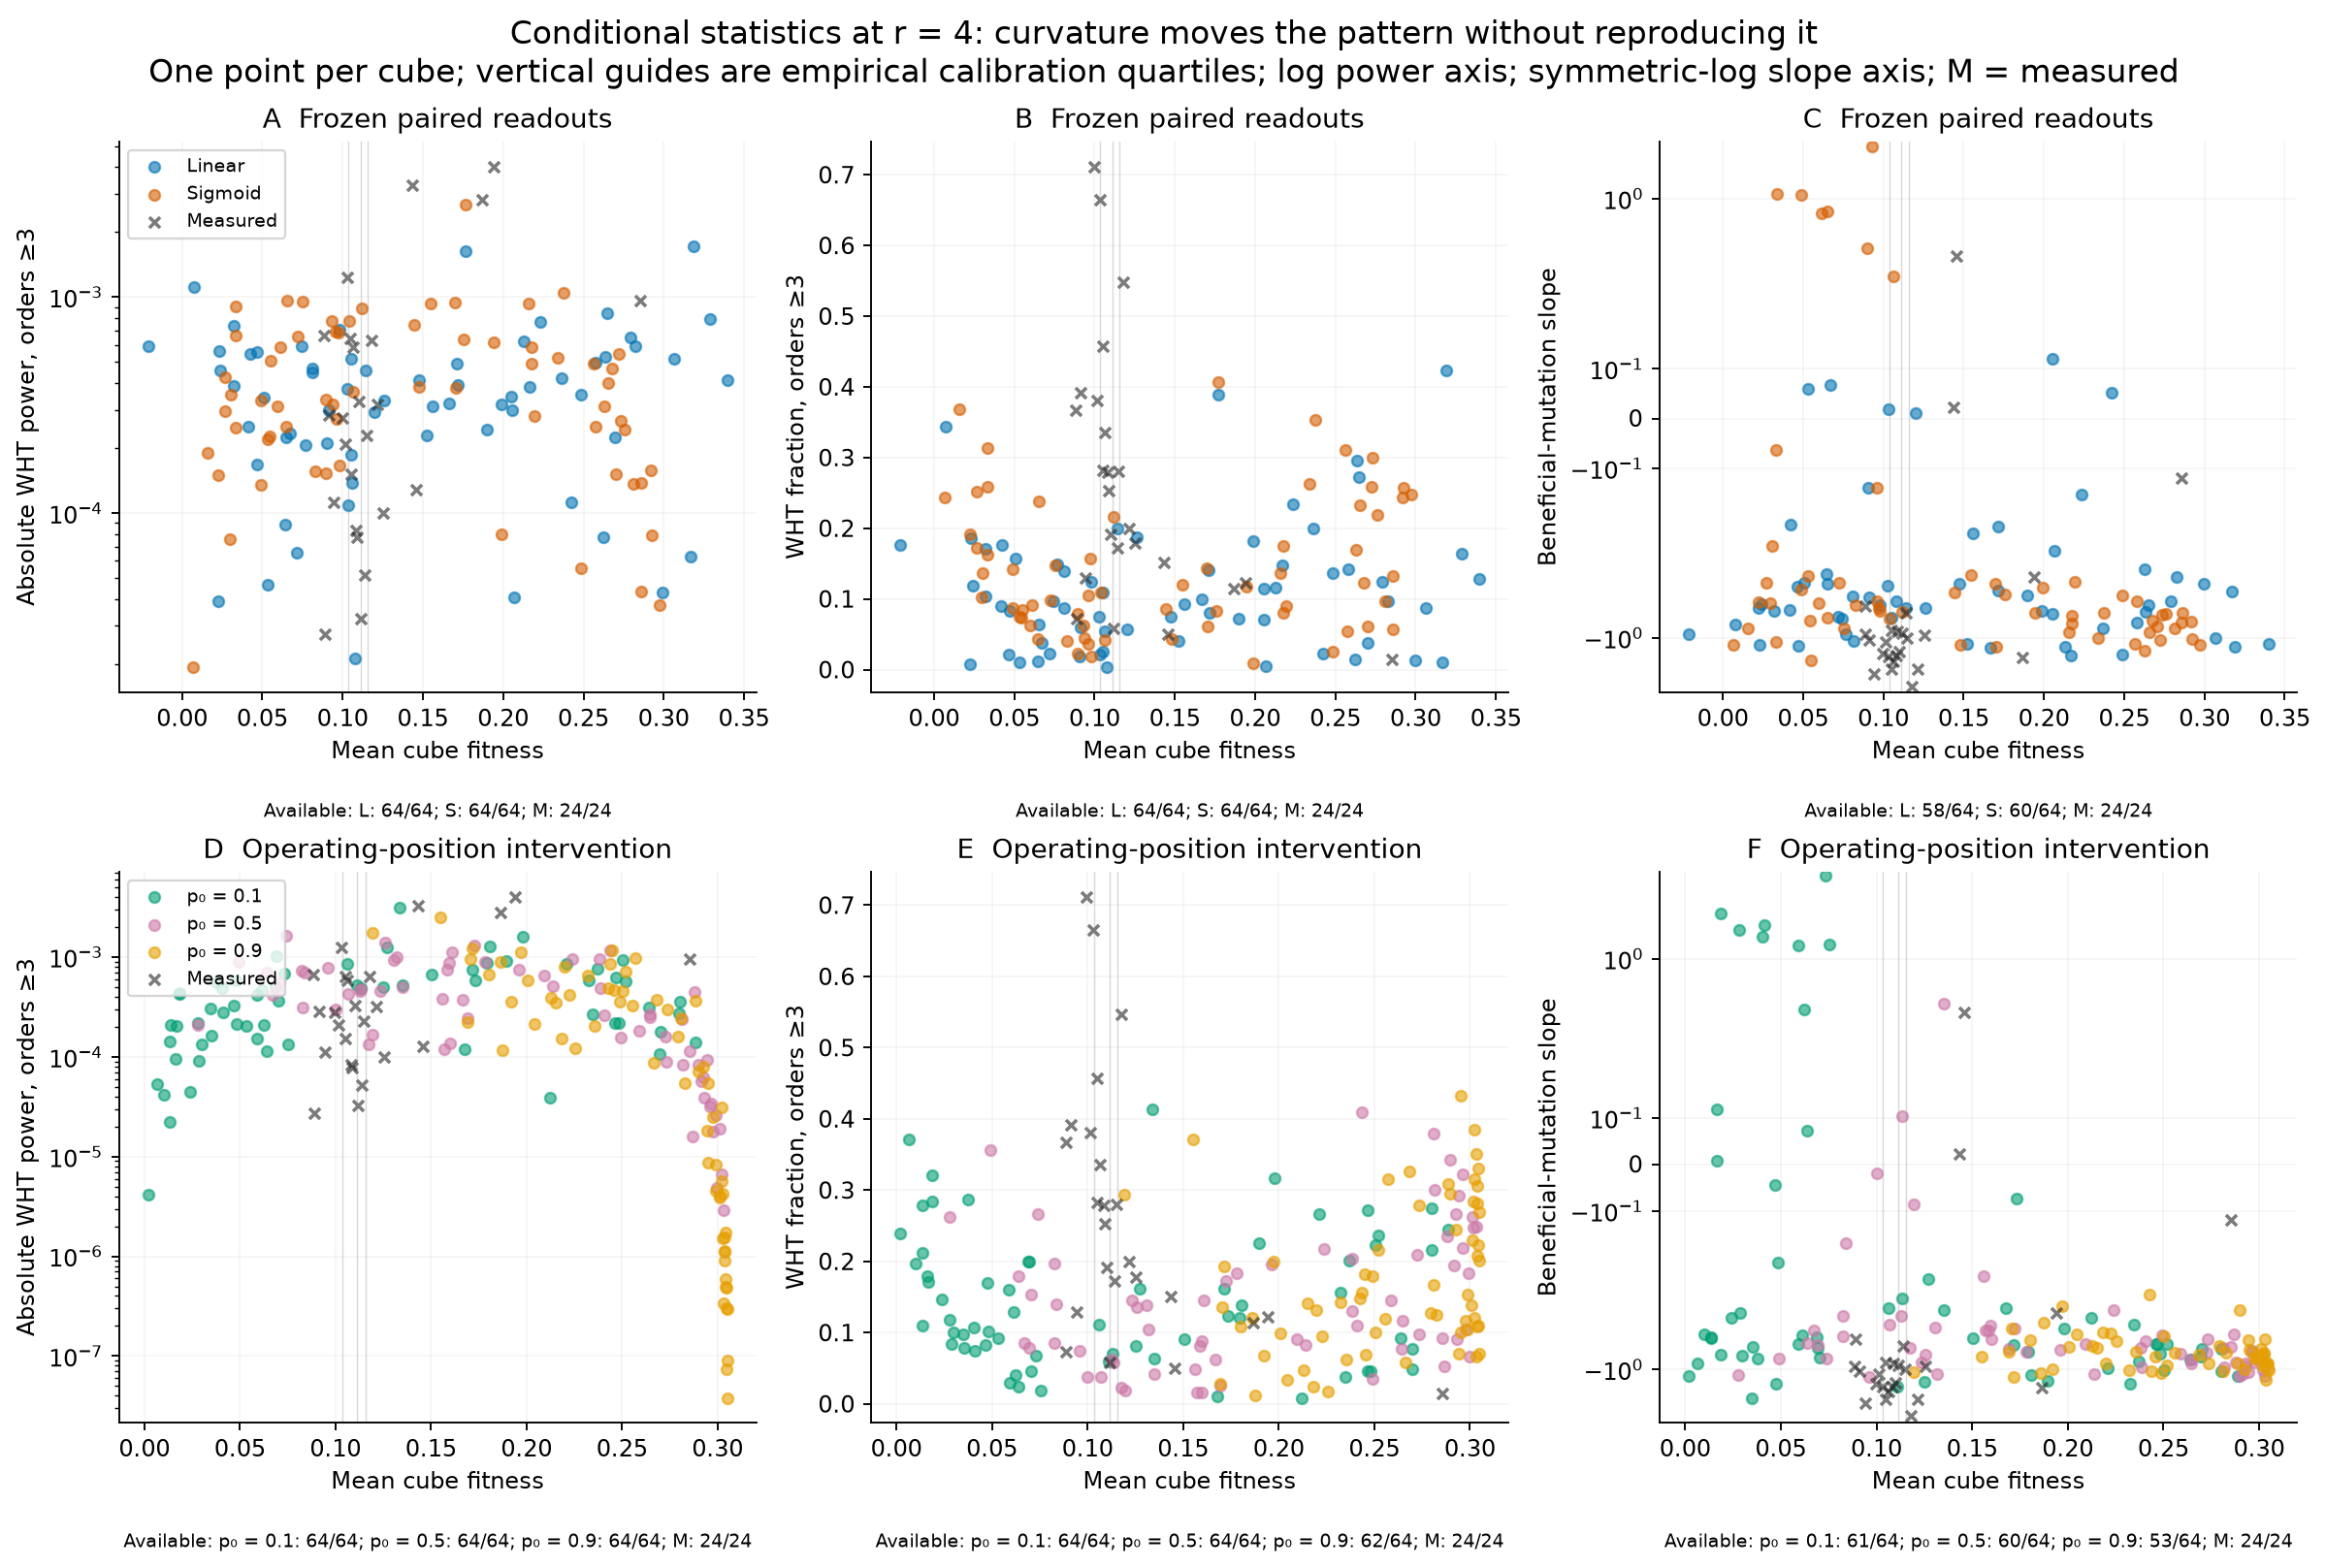

In [4]:
display(Image(filename=str(a.figure_conditional(ctx))))

## 3. The remaining mismatch is visible beyond a single distance

At r = 4, orders ≥2 account for a mean **0.662** of measured variance, versus **0.475 linear** and **0.520 sigmoid**. Mean absolute power at orders ≥3 is **7.21×10⁻⁴ measured, 4.13×10⁻⁴ linear, 4.55×10⁻⁴ sigmoid**; its empirical uncertainty is wide. Absolute power emphasizes high-variance cubes, whereas averaging per-cube fractions gives every resolved cube equal weight. The two summaries need not tell the same story.

The paired active-cube readouts preserve all **2,048 oriented edge signs per ratio** in float64, including ties. Accordingly the sigmoid cannot add exact sign reversals to this latent field. Its lower resolution-thresholded sign-epistasis fraction (**0.484 versus 0.525 linear; measured 0.575**) reflects thresholded edge magnitudes, not creation or deletion of underlying strict sign epistasis.

At r = 4 the point contrast favours sigmoid at all three resolutions, but the estimated advantage changes: **−0.0598 [−0.0936, −0.0250]** at 10⁻¹², **−0.0166 [−0.0647, +0.0734]** at 0.001, and **−0.1891 [−0.4989, +0.2660]** at 0.01. Resolution affects descriptor availability and thresholds; it cannot be chosen retrospectively to establish a biological conclusion.

**Figure 3.** A–B show absolute order-specific power and mean per-cube variance fractions with conditional intervals. C shows mean residuals divided by the frozen empirical calibration scale, with no uncertainty encoded. D retains the same frozen embedding while varying resolution. All marginal means, medians, counts and intervals are exported to tables.


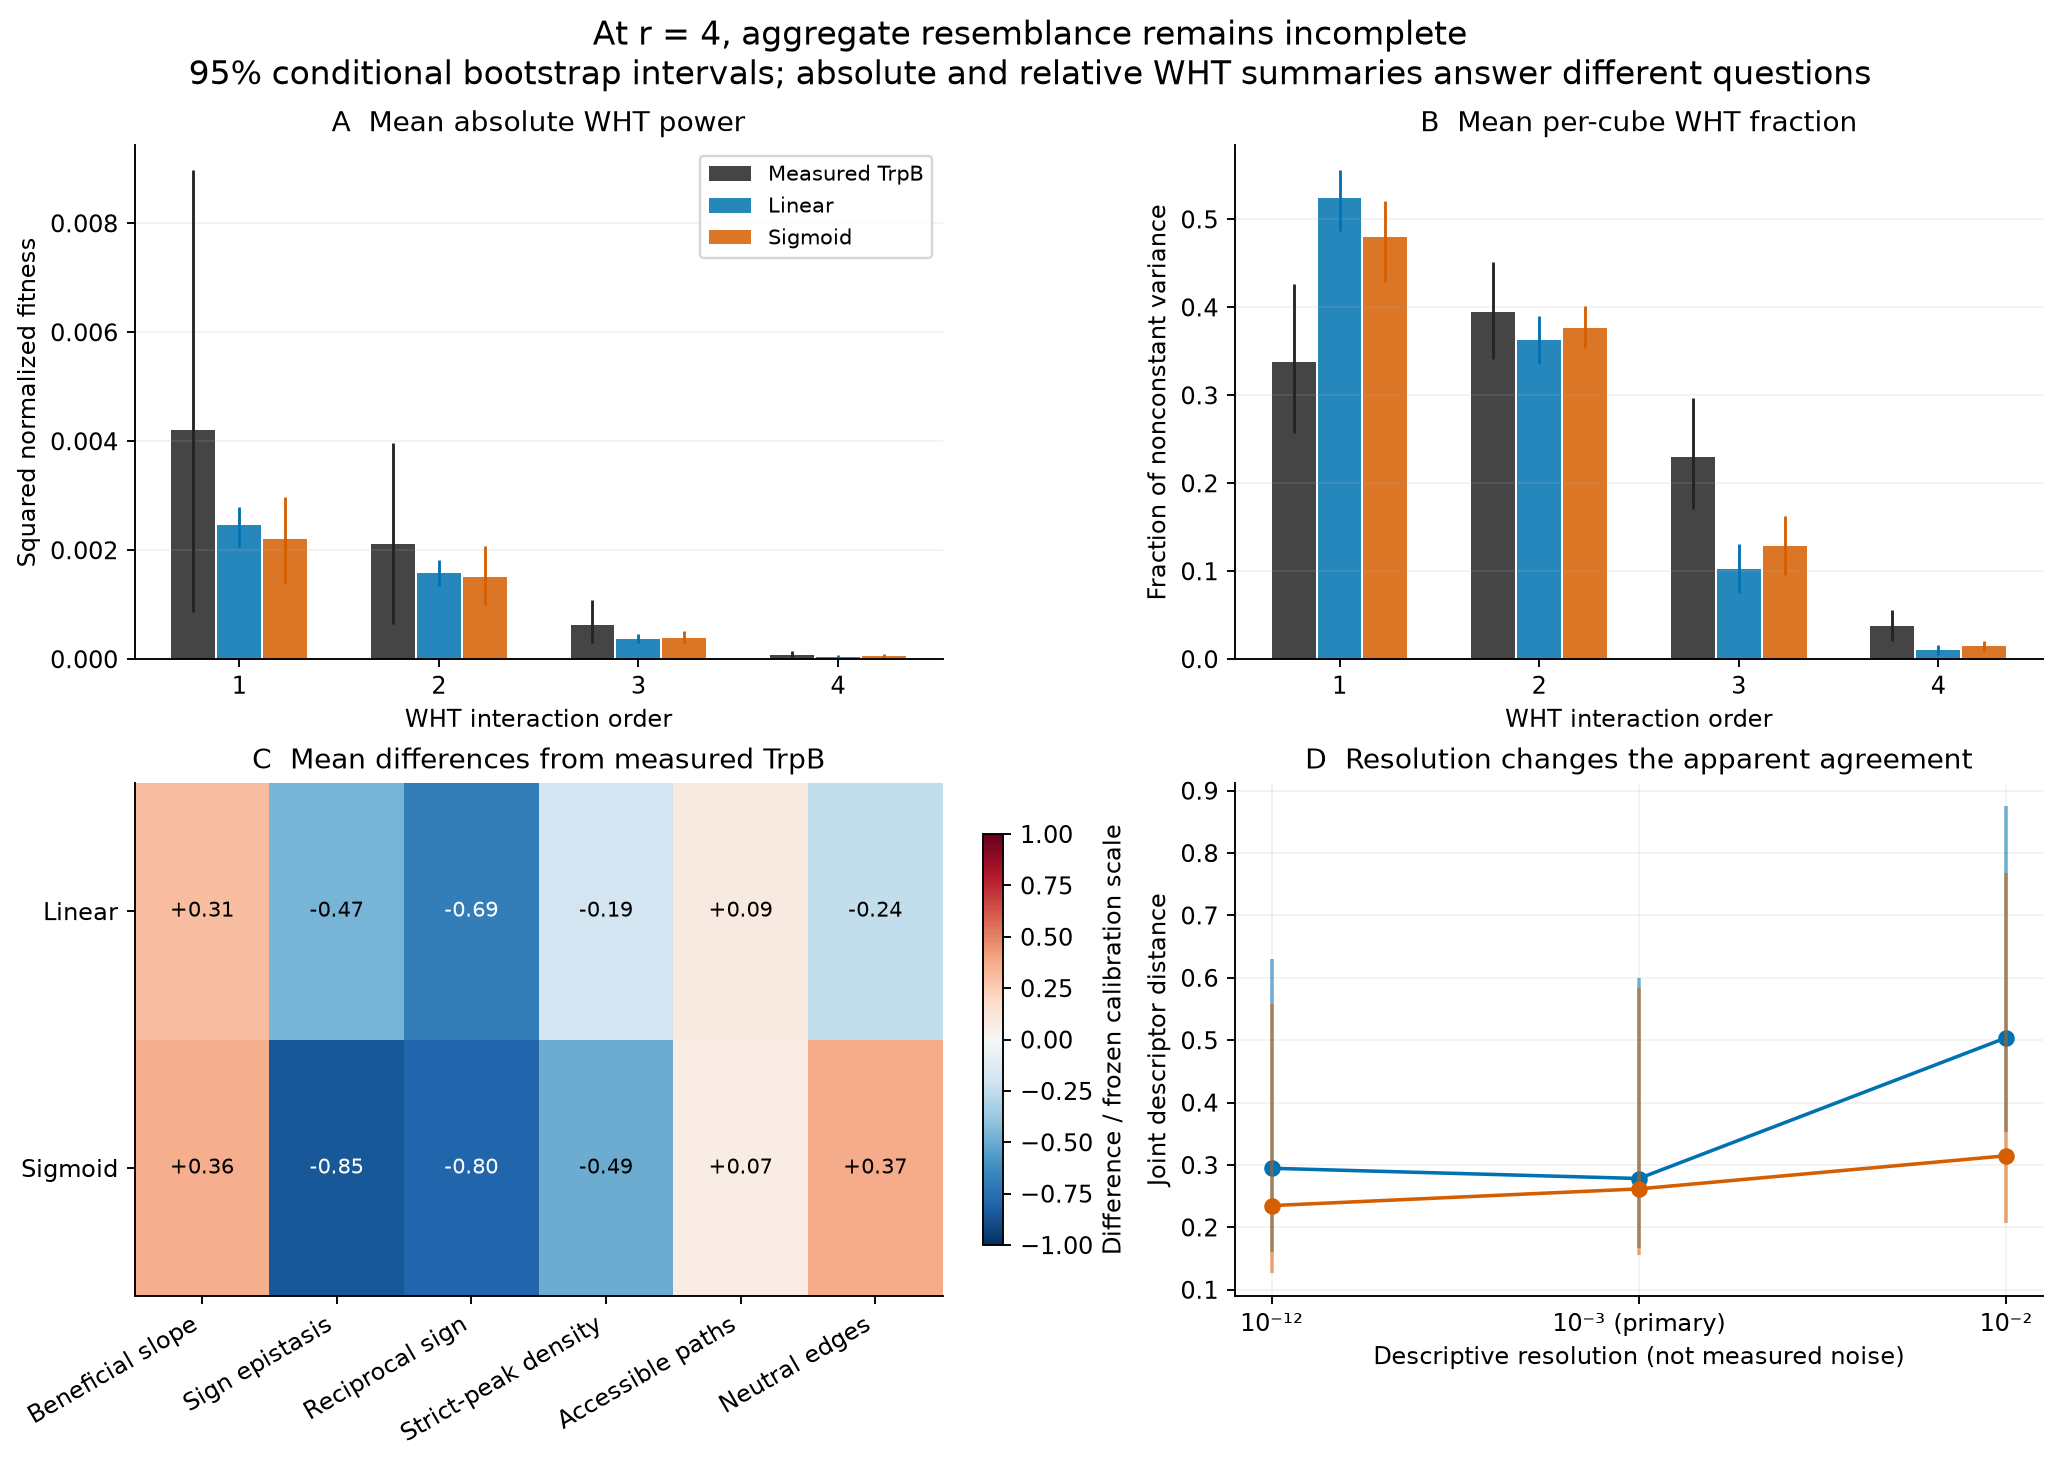

In [5]:
display(Image(filename=str(a.figure_fingerprint(ctx))))

## 4. Local observable variation survives, but four-site structure changes

The embedded comparison uses the selected r = 4 sigmoid (β = 0.5, p₀ = 0.2) and its same-r linear partner, with all affine coefficients frozen. It crosses lengths 32, 128 and 512, two reference ranks, two site-selection policies and four anchor ensembles. There are **1,152 latent cubes**, each queried through both readouts. Each plotted condition contains 24 cubes from three seeds and two libraries per seed; these are not 24 independent landscapes. The same numeric seed labels are reused across lengths and ranks.

At length 512 and reference rank 0.5, all **24/24 reference-anchored cubes per site policy** have resolved spectra. The sigmoid's mean edge RMS is **0.0716** at uniformly sampled sites and **0.0775** on a shared order-four support. Thus increasing length alone does not eliminate observable local variation. This refines the interpretation of the earlier random-sequence scaling panel.

However, on uniformly selected sites the linear high-order WHT fraction is essentially zero at lengths 128 and 512. At length 512 near the reference, a shared-support library retains mean linear high-order fraction **0.0105**, versus numerical zero for uniform sites. Sigmoid curvature raises these to **0.0229** and **0.0070**, still far below the active-four-site empirical mean 0.2668. That empirical comparison is contextual: TrpB's four assayed sites are not established to follow either synthetic site-sampling policy. No empirical interaction map was fitted.

**Figure 4.** Reference rank 0.5, frozen readouts. Solid curves use uniformly sampled sites; dashed curves place the four sites on a sampled existing order-four support. Colours identify anchor ensembles. Edge RMS averages within-cube RMS values and uses a stable computation. WHT means include resolved cubes only; the right column shows the denominator. Curves are descriptive means over three seeds; individual seed means are retained in `tables/embedded_seed_means.csv`.


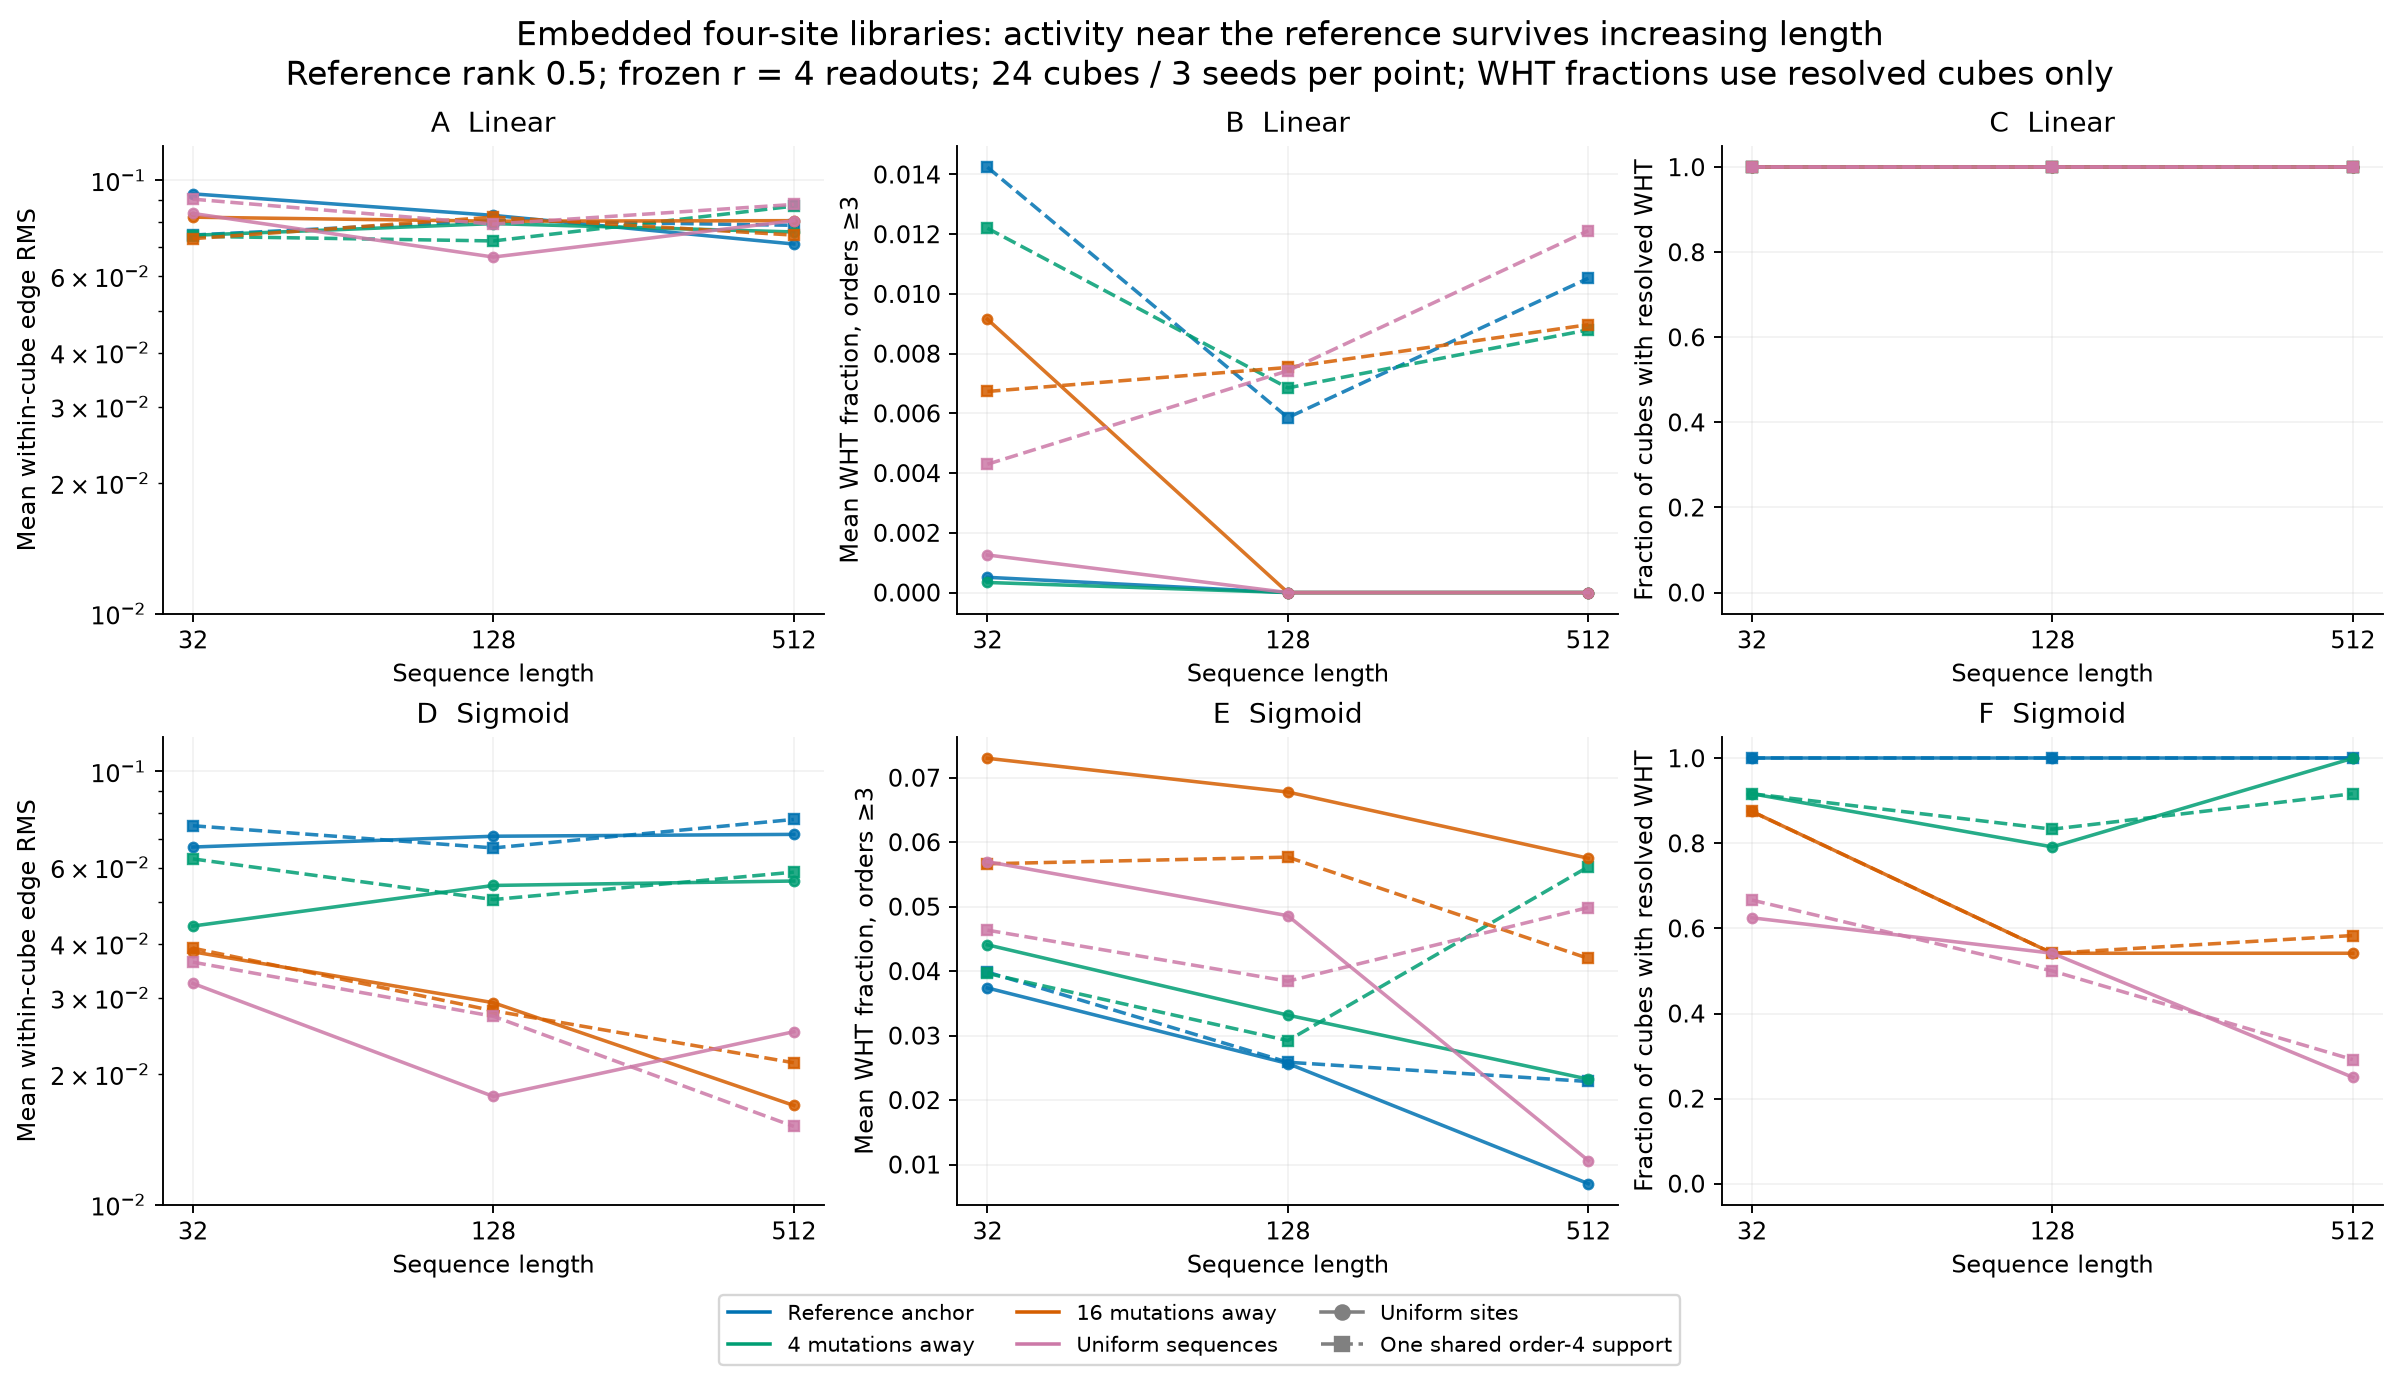

In [6]:
display(Image(filename=str(a.figure_embedded(ctx))))

## 5. Saturation is strongly conditional on the reference and neighbourhood

At length 512, rank-0.5 **uniform random** backgrounds have only **6/24** resolved cubes at uniform sites and **7/24** on a shared support; about **76–78% of edges** are below the primary resolution. At rank 1, uniform backgrounds are unresolved at every tested length. Their effects are nonzero but too small to resolve at length 32, and all sampled effects are exactly zero in float64 at lengths 128 and 512. Reference-anchored libraries remain resolved in all rank/length/site-policy combinations.

Rank 1 chooses a favourable additive allele at every reference site. The specified reference is anchored by construction; it is not an independently selected functional protein, biological wild type, or certified optimum. Distance labels refer to the cube's anchor, not all 16 vertices. The shared-support control mitigates loss of latent high-order structure among chosen sites; it does not cure saturation or establish realistic site selection.

**Figure 5.** Colour reports mean neutral-edge fraction, defined by |effect| ≤ 0.001. Cell annotations separately report the number of resolved spectra and the percentage of exactly zero float64 edges. These distinguish small observable effects from numerical collapse; neither is interpreted as an empirical measurement-error estimate.


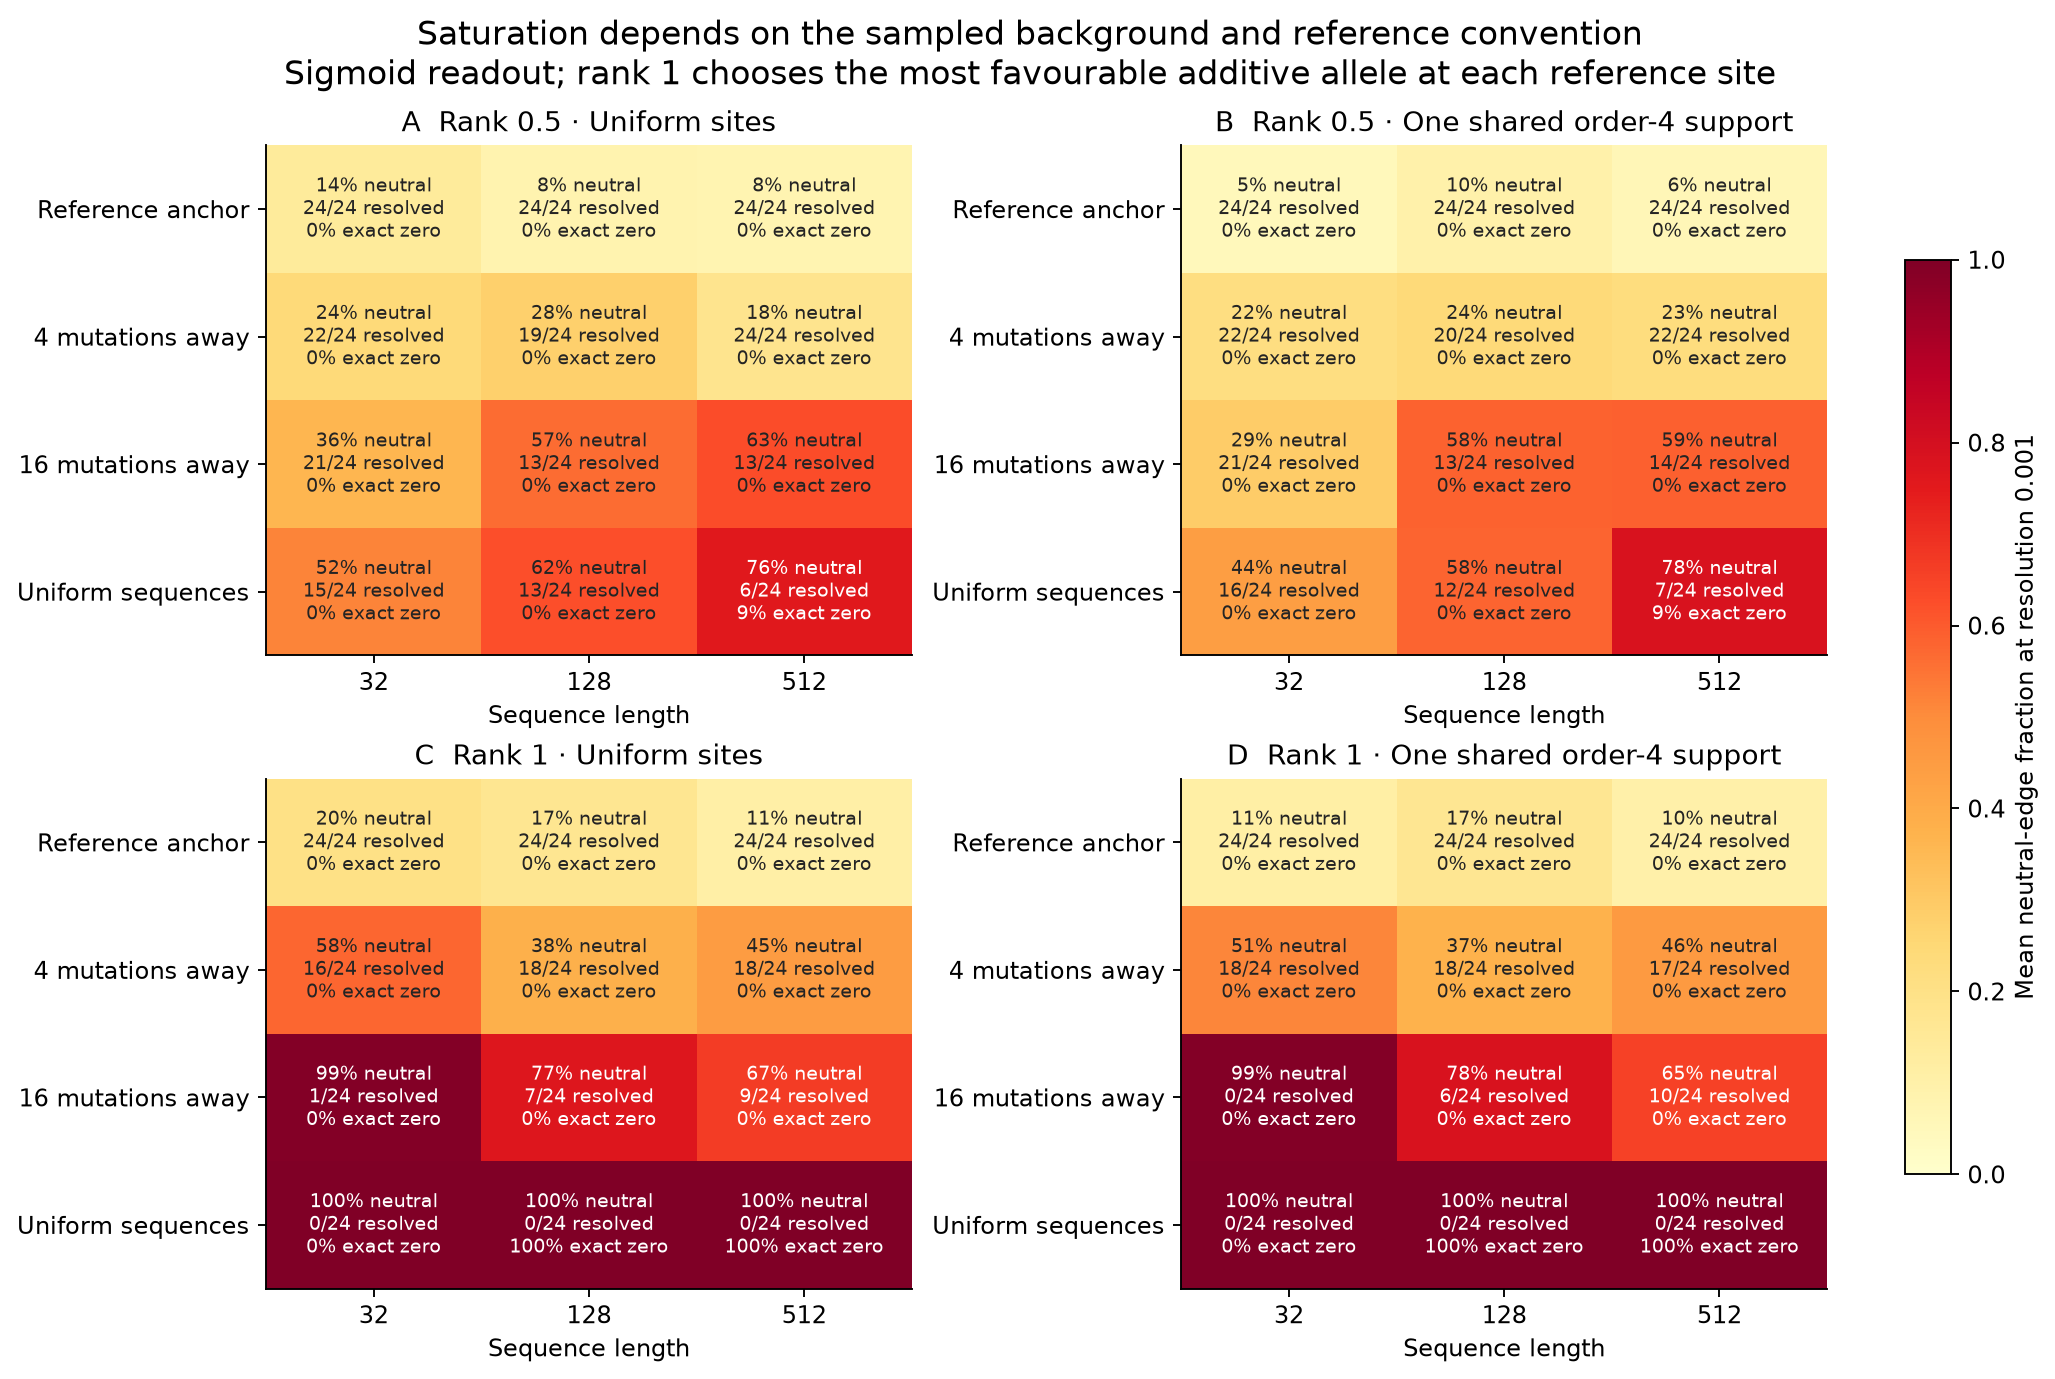

In [7]:
display(Image(filename=str(a.figure_saturation(ctx))))

## Interpretation and scope

This RUN supports an interacting latent field and a strong role for where and how landscapes are sampled. It provides only weak primary-resolution evidence for added explanatory value from sigmoid curvature after comparable amplitude calibration. It also shows that a tractable large-sequence generator can retain local variation without preserving the four-site aggregate statistics of its calibration setting. “Scalable” computational construction and “empirical-looking” statistics are distinct questions.

The record remains limited to one assay and complete four-site binary cubes. Measurement errors are unavailable: empirical WHT may include measurement variance, and regressions of effects on shared background measurements can be biased toward negative slopes. The measured diminishing-returns slope is therefore a descriptive target, not an identified error-free biological constant. Fixed order weights, a finite curvature grid and a boundary-selected interaction ratio leave model adequacy and physical interpretation unresolved. No result here infers specific interactions, whole-protein WHT, or arbitrary-length statistical invariance.

The interpretation follows the prospective [paired-readout protocol](../../../experiments/2026-10-07_EXP-065_aggregate-thermodynamic-gnk-calibration/paired_readout.md) and its literature context: [Otwinowski et al. (2018)](https://doi.org/10.1073/pnas.1804015115) on nonlinear latent maps; [Reddy & Desai (2021)](https://doi.org/10.7554/eLife.64740) on diminishing returns from complex traits; and [Sailer & Harms (2017)](https://doi.org/10.1534/genetics.116.195214) on phenotype scale and high-order epistasis. These papers motivate the comparison; the evidence above is RUN-166's, not an attribution of its findings to those papers.


## Reproducibility and verification

The notebook independently checks 20 output/log checksums, nine submitted-source hashes and two input hashes; all 768 saved empirical measurements against the prepared table; all 40 candidate affine calibrations and losses; and all 24 confirmation distances. It reconstructs 3,312 observable cubes from saved latent values, recalculates the ten distance descriptors plus WHT orders for all 9,936 resolution-specific rows, and verifies 105,984 oriented edges. It checks genotype exclusion, seed separation, exact pairing and frozen transfer coefficients. This is replay of saved latent fields; it does not claim cross-platform regeneration of GNK coefficients.

Read [README.md](../README.md) for data restoration, dependencies and execution. The canonical notebook retains its executed outputs; all five figures are exported as PNG and vector PDF. `tables/audit.json` gives numerical tolerances, maximum discrepancies and environment versions. Numerical audit assertions check data consistency, not scientific success criteria. Repository-wide strict checks could not complete because historical cloud-backed files timed out; no global strict-check pass is claimed. No RES or CLAIM is created by this analysis.


In [8]:
# Audited numerical findings and artifact checks, retained for machine-readable reuse.
a.dump_json(a.TABLES / 'metrics.json', {
    'run': 'RUN-166', 'analysis': 'ANA-064',
    'selected_pair': ctx['selected_parameters']['embedded_pair'],
    'paired_contrasts': ctx['contrasts'].to_dict('records'),
    'operating_position': ctx['operating_summary'].to_dict('records'),
    'analysis_source_sha256': a.sha256(Path(a.__file__)),
    'interpretation': 'Descriptive aggregate comparison; no fitted empirical interactions or scientific success gates'
})
artifacts = sorted(p for p in a.FIGURES.iterdir() if p.suffix in {'.png', '.pdf'})
assert len(artifacts) == 10 and all(p.stat().st_size > 1000 for p in artifacts)
display([str(p.relative_to(a.ANALYSIS)) for p in artifacts])
display(ctx['audit']['bootstrap'])

['figures/01_paired_readouts.pdf',
 'figures/01_paired_readouts.png',
 'figures/02_conditional_statistics.pdf',
 'figures/02_conditional_statistics.png',
 'figures/03_aggregate_fingerprint.pdf',
 'figures/03_aggregate_fingerprint.png',
 'figures/04_embedded_neighbourhoods.pdf',
 'figures/04_embedded_neighbourhoods.png',
 'figures/05_saturation_and_availability.pdf',
 'figures/05_saturation_and_availability.png']

{'draws': 2000,
 'seed': 664001,
 'units': '24 empirical cubes and 8 synthetic seed clusters of 8 cubes; common resampling weights across readouts and ratios; calibration frozen',
 'limitations': 'Percentile descriptive intervals; no refitting, measurement-error correction, or empirical allele/site-dependence model; embedded panel has only 3 seeds, no bootstrap interval'}